In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import os
import sys
import astropy as ast
import matplotlib.pyplot as plt
import pandas as pd
import glob
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from matplotlib.colors import LogNorm, Normalize
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
import matplotlib.path as mpath
from pathlib import Path
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import MultipleLocator, AutoMinorLocator, FormatStrFormatter, FuncFormatter
import mesa_reader as mr
fourpointstar = mpath.Path.unit_regular_star(4)
sevenpointstar = mpath.Path.unit_regular_star(7)
eightpointstar = mpath.Path.unit_regular_star(8)
from view_and_clean_newlcs_oct26 import df_extract, grid_plotter, grid_plotter_offset_corrected
from metrics_newlcs_oct26 import fit_plotter_flux, compute_lomb_scargle, plot_periodogram, info, plot_phase_fold_binned, plot_phase_fold

In [5]:
# sample = pd.read_csv(
#     './summary_results09222026.csv'
# ).set_index('star_idx', drop=False)
offsets = pd.read_csv('offsets.csv')
coords = pd.read_csv('merged_smc_lmc_coords_all.csv', comment='#', sep="\\s+", names=['RA', 'DEC'])
target_mapping = pd.read_csv('asassn_lc_data/sub_oct2026/YSG_V3_individual_20261016/target_mapping.csv')

In [17]:
offsets_nolcs = offsets[offsets['discard_lc_post_newlcs_oct26'] == 1.0]
print(f"Number of targets with no light curves: {len(offsets_nolcs)}")
print(f"List of targets with no light curves: {offsets_nolcs['target'].tolist()}")

Number of targets with no light curves: 21
List of targets with no light curves: [32, 320, 401, 587, 737, 777, 792, 824, 839, 1063, 1140, 1141, 1142, 1146, 1148, 1149, 1150, 1151, 1153, 1154, 1175]


In [3]:
# check that target mapping matches sample
for index in range(0, 1270):
    RA = coords['RA'].iloc[index]
    dec = coords['DEC'].iloc[index]
    # match index to target mapping input column:
    target_row = target_mapping[target_mapping['ra'] == RA]
    if not target_row.empty:
        if target_row['input_row'].values[0] != index:
            print(f"Index mismatch for RA {RA}: target mapping input {target_row['input_row'].values[0]} vs index {index}")
            

7006


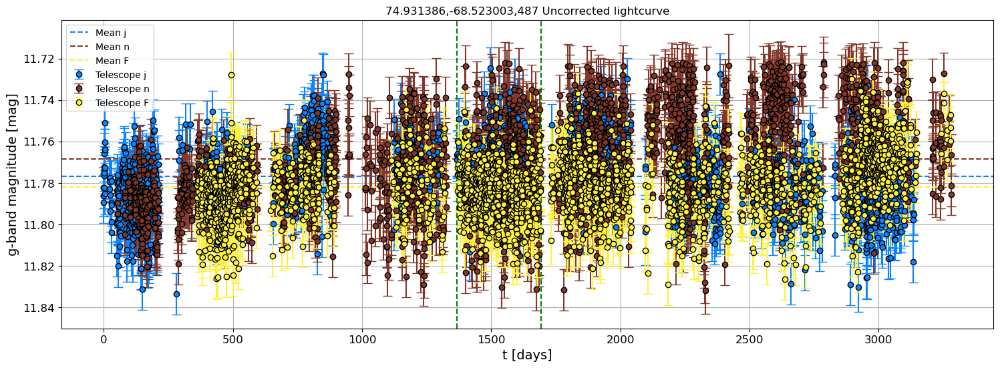

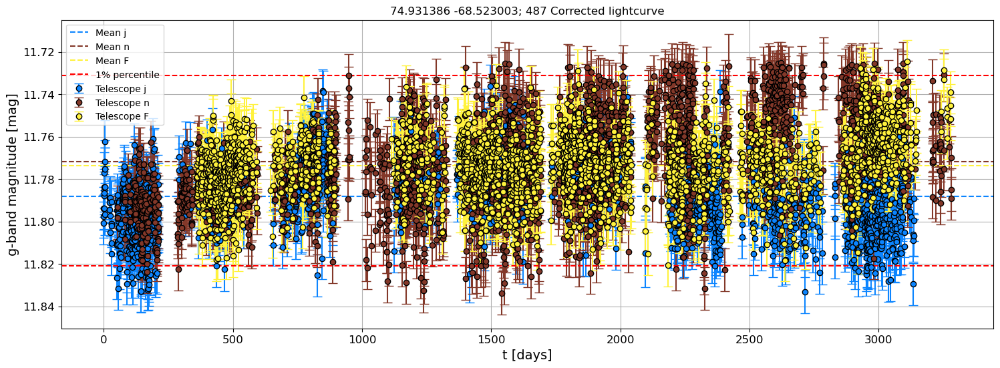

Best frequency: 0.000853 1/day, Best period: 1172.56 days, Max power: 0.053, False alarm probability: 5.484e-78
False alarm level for 1.0%: 4.508e-03
Grid sampled at 62867 points


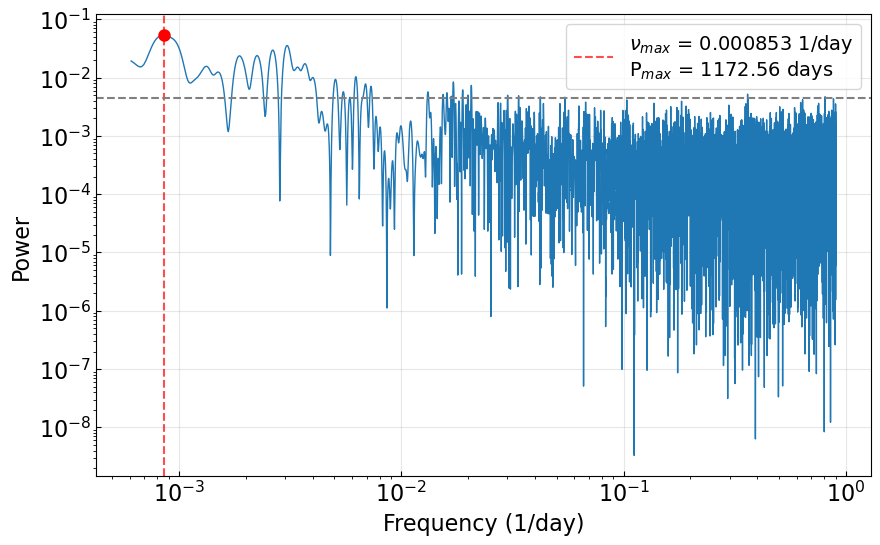

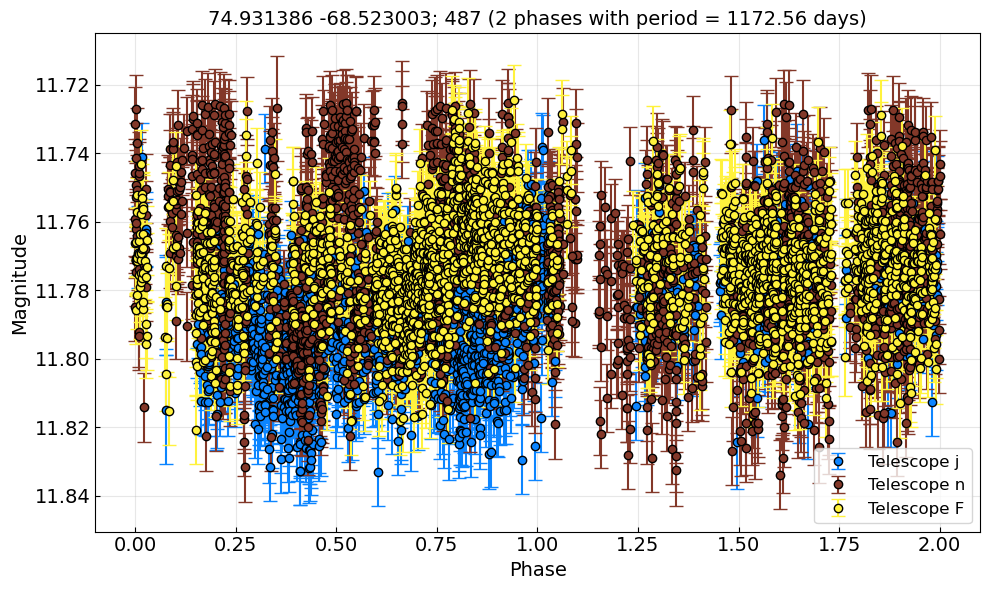

Average scatter (amplitude) per 10 point phase bin: 3.164 mJy


/opt/anaconda3/envs/ysg/lib/python3.13/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/opt/anaconda3/envs/ysg/lib/python3.13/site-packages/numpy/_core/_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


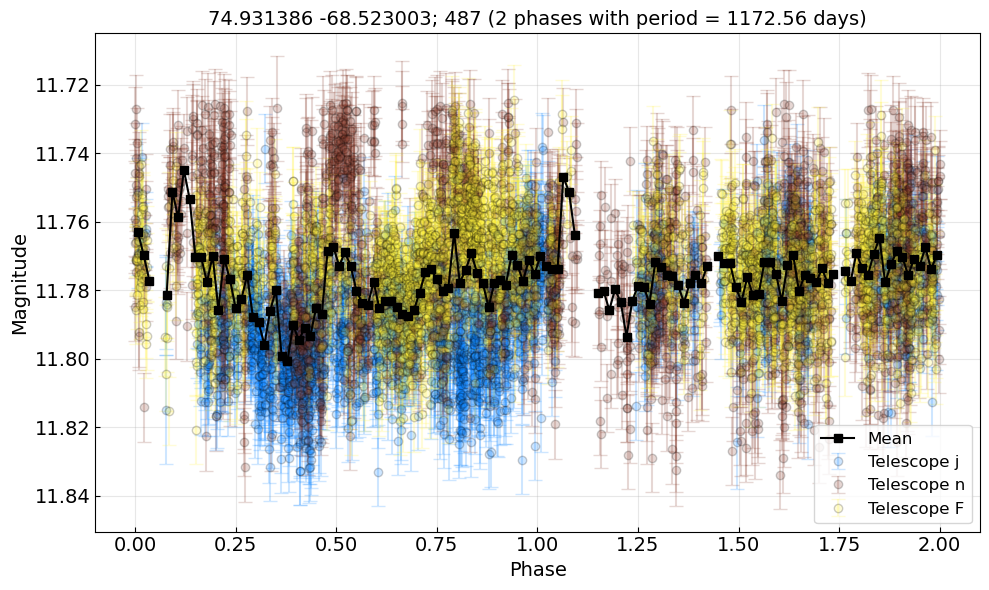

Average scatter (amplitude) per 10 point phase bin: 3.164 mJy
[0.00085283 0.00132494 0.00149662 0.00186859 0.00224056 0.00264114
 0.00307033 0.00341369 0.00368551 0.00400025 0.00505893 0.00548813
 0.0058744  0.00624637 0.00690447 0.00730505 0.01318501 0.01541682
 0.01606061 0.01677593 0.0171622  0.01889329 0.01993766 0.02066729
 0.03009525 0.03371479 0.04222714 0.05445916 0.36133289 0.80636417]
Amplitude metrics:
	Lower 5% percentile: 68.640 mJy, 11.744 mags
	Upper 5% percentile: 72.877 mJy, 11.809 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 5% of data) (g-band: True): 4.236 mJy, 0.065 mags
Amplitude metrics:
	Lower 1% percentile: 67.874 mJy, 11.731 mags
	Upper 1% percentile: 73.716 mJy, 11.821 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 1% of data) (g-band: True): 5.843 mJy, 0.090 mags
	Largest amplitude of variability (g-band: True): 7.101 mJy, 0.109 mags
	Average amplitude across all periods: 6.662 mJy
	Standard d

In [20]:
n = 487
df, telescopes = df_extract(n)
print(len(df))
info(n)

In [5]:

# print(df["qual"].dtype)
# print(df["qual"].describe())
# print(df["qual"].isna().sum(), "NaNs out of", len(df))
# print(df["qual"].value_counts(dropna=False).head(10))
# test out 'qual' column
# q = df["qual"]
# df = df[q >= 0]  # Keep only rows where 'qual' is greater than or equal to 0
# print(f"Number of data points after filtering by 'qual' >= 0: {len(df)} out of {len(q)} total data points.")
# good = df[(q & 55) == 0]
# print(f"Number of good data points: {len(good)} out of {len(df)} total data points.")



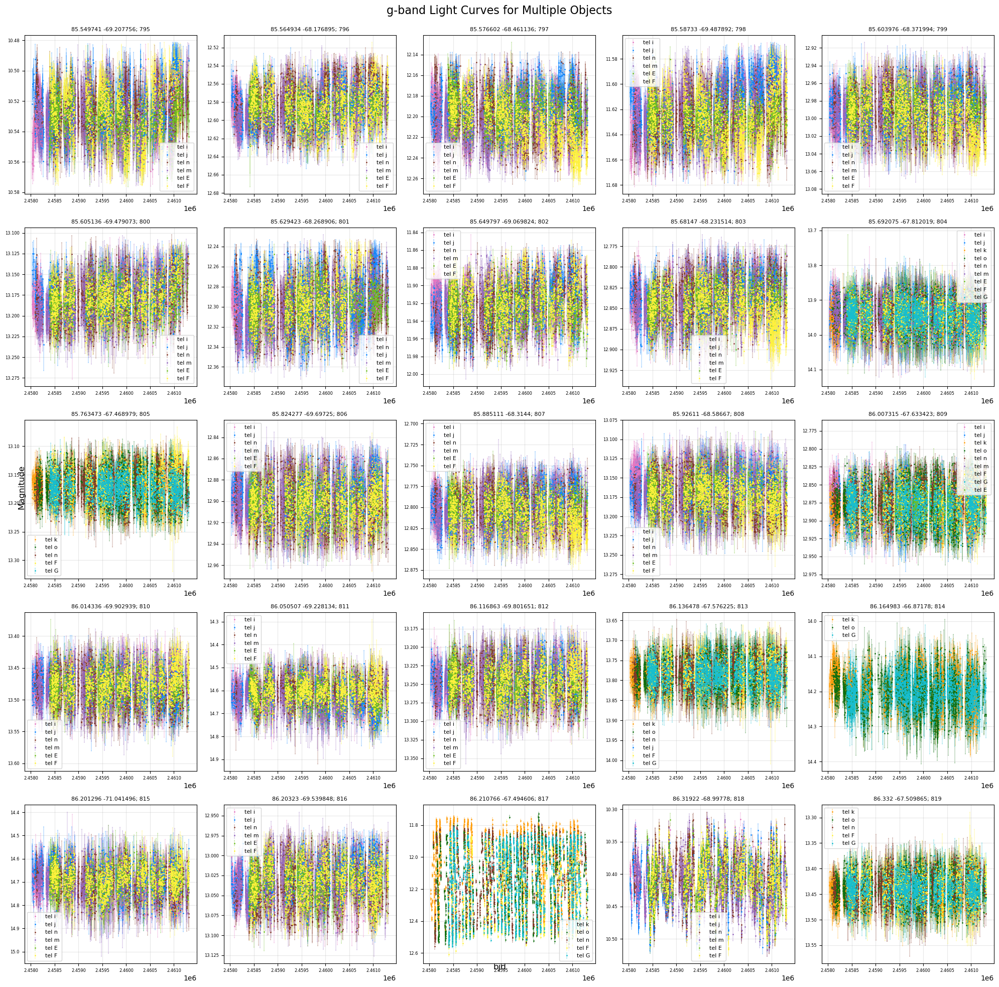

In [6]:
grid_plotter_offset_corrected(1170 - 25 * 15)

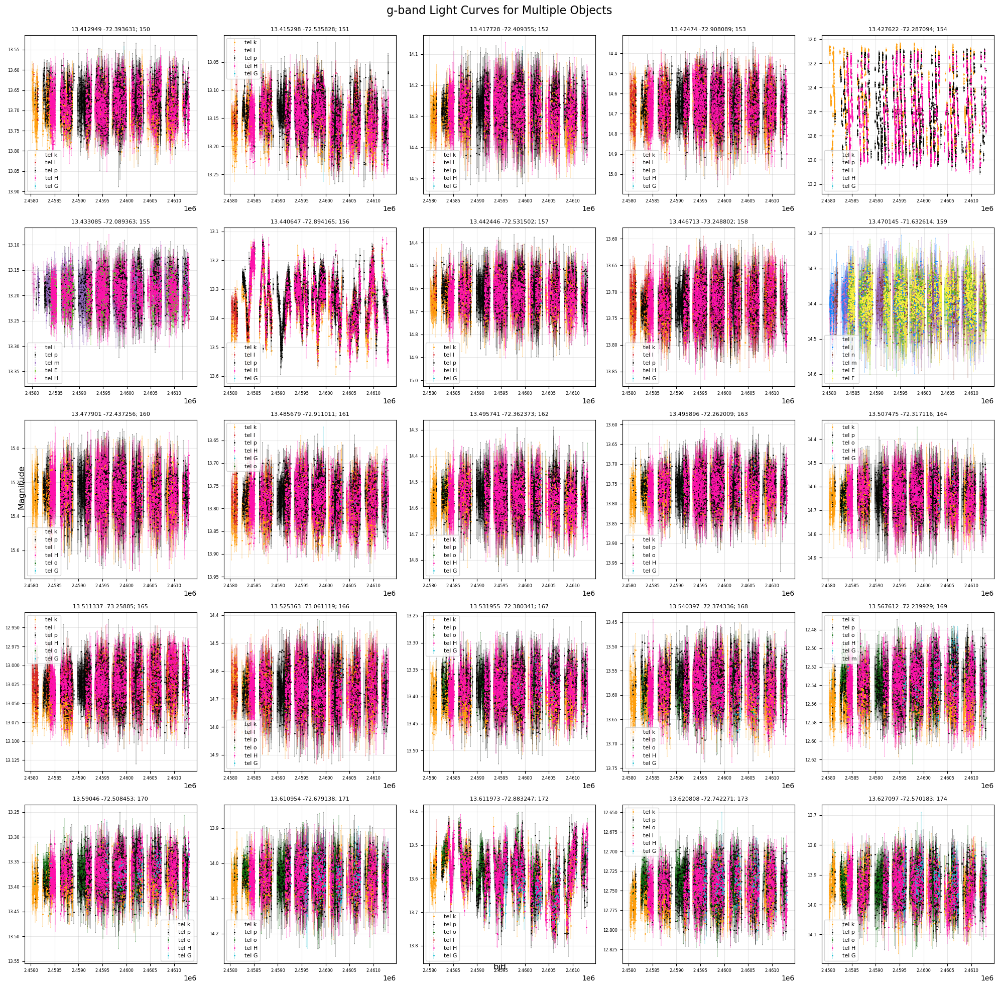

In [7]:
grid_plotter_offset_corrected(150)

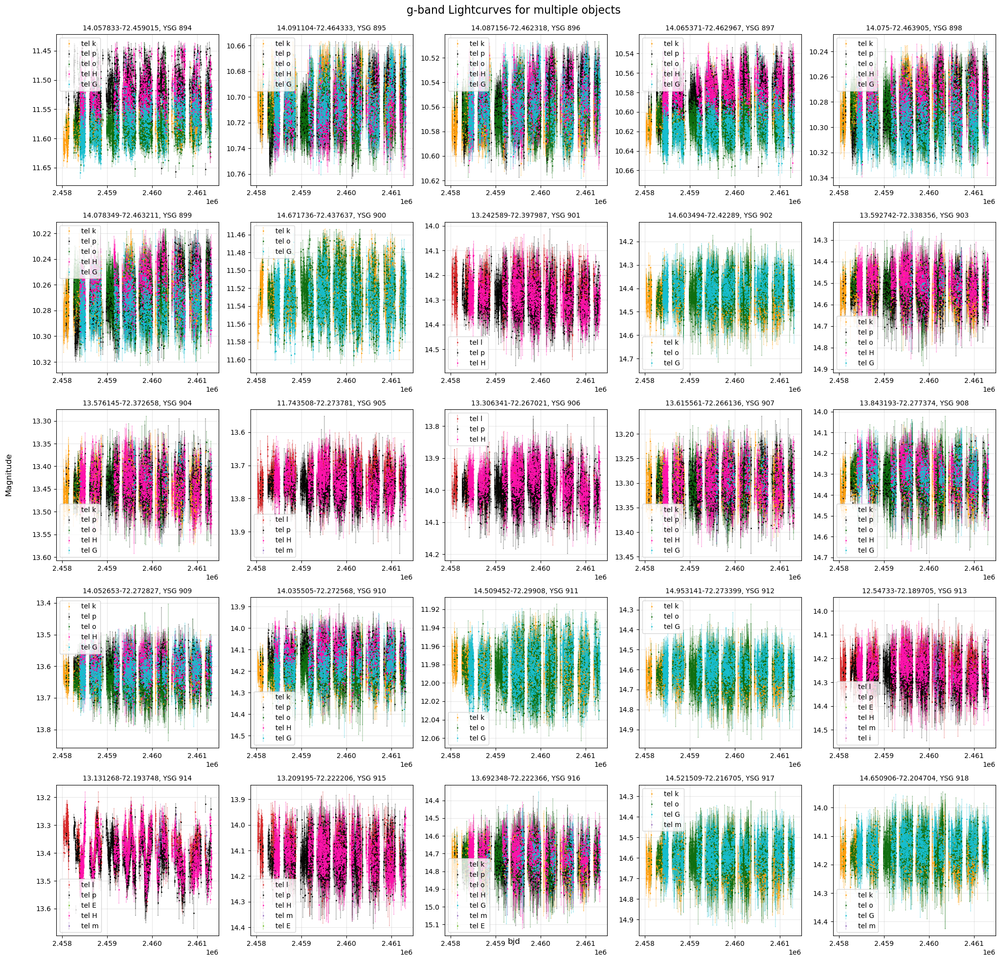

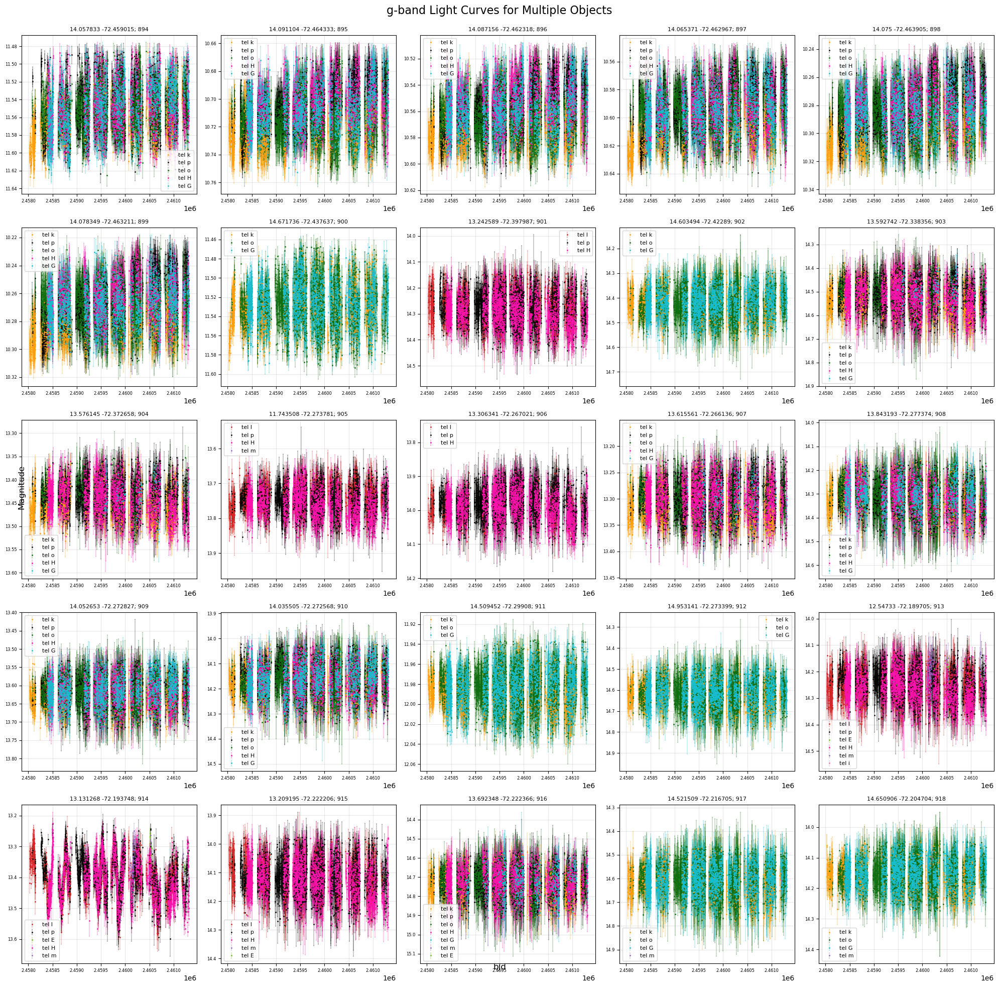

In [8]:
grid_plotter(894)
grid_plotter_offset_corrected(894)

In [13]:
sample_oct = pd.read_csv(
    './summary_results10202026.csv'
).set_index('star_idx', drop=False)
sample_sept = pd.read_csv(
    './summary_results09222026.csv'
).set_index('star_idx', drop=False)

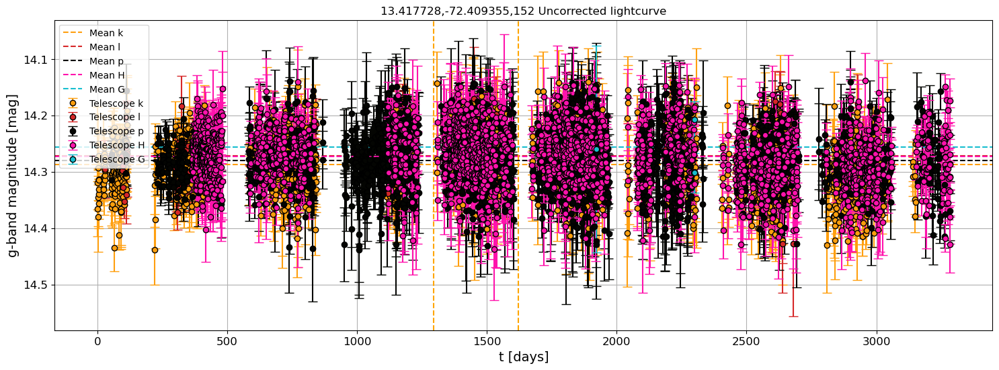

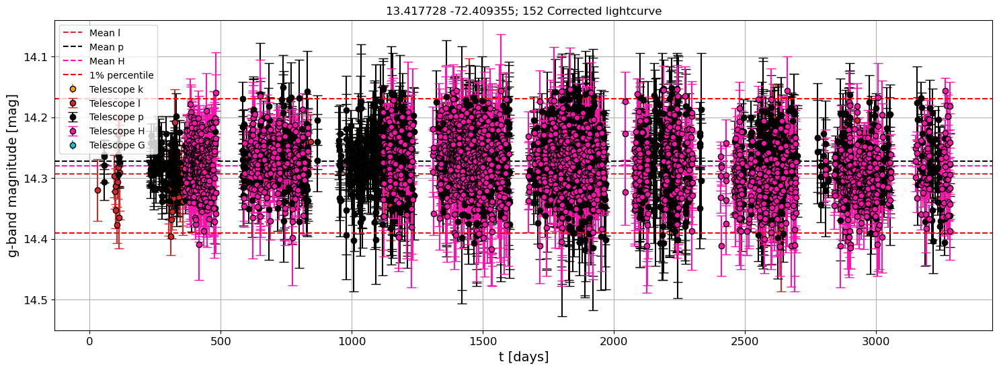

Best frequency: 0.002410 1/day, Best period: 414.99 days, Max power: 0.018, False alarm probability: 1.903e-14
False alarm level for 1.0%: 6.378e-03
Grid sampled at 43089 points


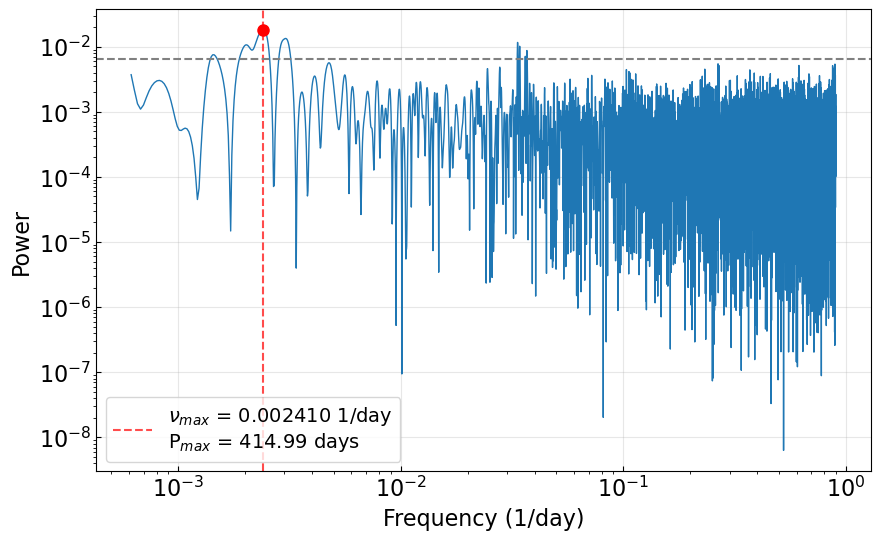

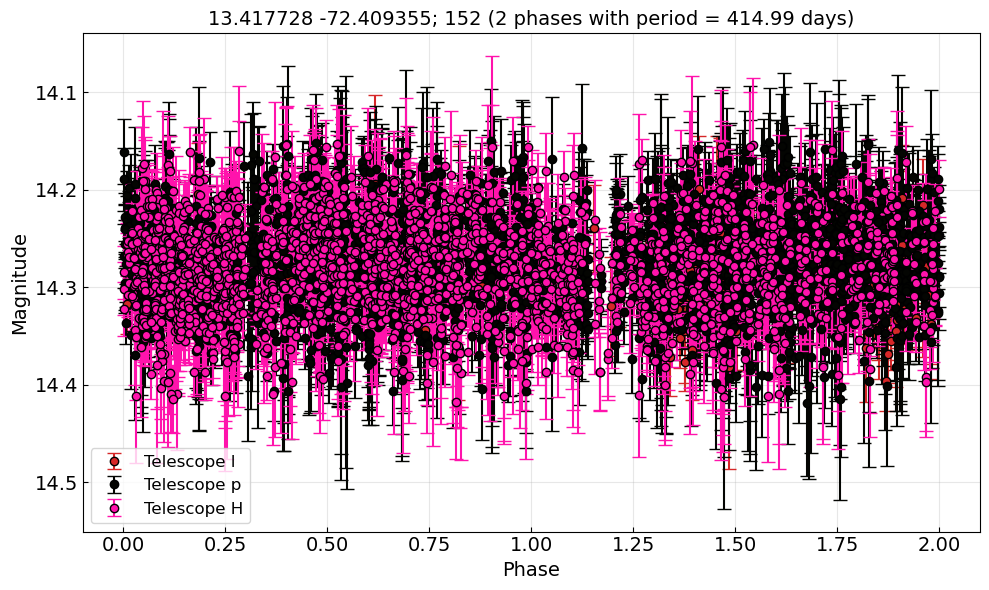

Average scatter (amplitude) per 10 point phase bin: 0.880 mJy


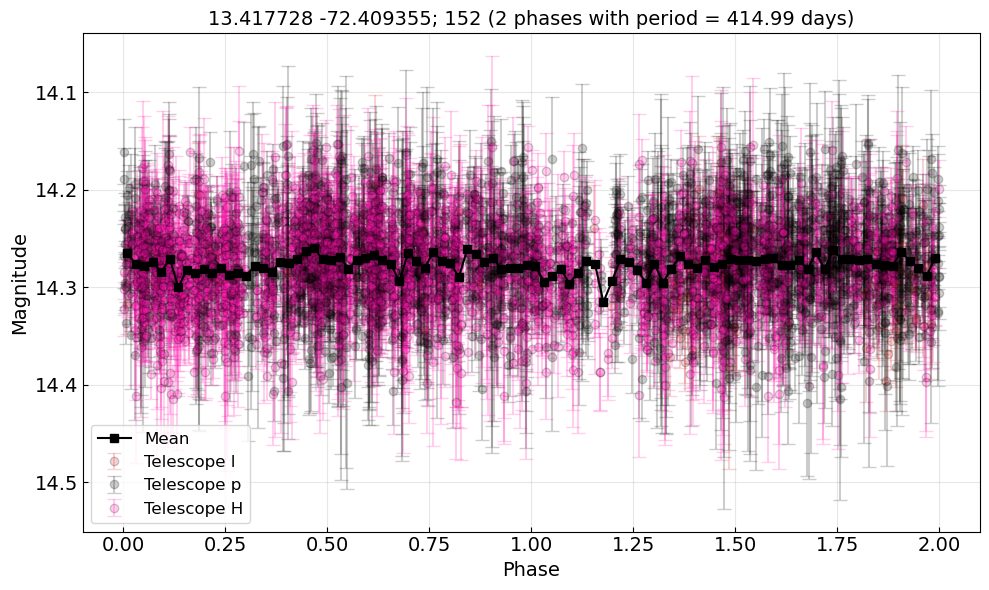

Average scatter (amplitude) per 10 point phase bin: 0.880 mJy
[0.00144954 0.00203399 0.0024097  0.0030359  0.03348993 0.03422049
 0.03626607 0.03687139]
Amplitude metrics:
	Lower 5% percentile: 6.582 mJy, 14.200 mags
	Upper 5% percentile: 7.589 mJy, 14.354 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 5% of data) (g-band: True): 1.007 mJy, 0.155 mags
Amplitude metrics:
	Lower 1% percentile: 6.362 mJy, 14.169 mags
	Upper 1% percentile: 7.806 mJy, 14.391 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 1% of data) (g-band: True): 1.444 mJy, 0.222 mags
	Largest amplitude of variability (g-band: True): 1.739 mJy, 0.268 mags
	Average amplitude across all periods: 1.682 mJy
	Standard deviation of amplitudes: 0.027 mJy
	Average amplitude (1.682 mJy) is greater than 5 sigma (0.027 mJy). This indicates consistent variability across periods.


In [7]:
info(152)

In [20]:
lunar_oct = sample_oct[(sample_oct['best_period'] < 30.0) & (sample_oct['best_period'] > 29)]
print(len(lunar_oct))
print(lunar_oct['star_idx'].values)
lunar_sept = sample_sept[(sample_sept['best_period'] < 30.0) & (sample_sept['best_period'] > 29)]
print(len(lunar_sept))
# not 982, 436, those are cepheids

10
[ 436  627  651  939  982 1048 1054 1139 1141 1143]
99


5637 rows read from /Users/shannonbowes/Research/ysg/candidates_and_lcs/2022_asassn_lc_data/asassn_lc_data/sub_oct2026/YSG_V3_individual_20261016/lightcurves/YSG_0651_g.csv
Number of data points after filtering by 'qual' >= 0: 5373
Number of data points after filtering by 'qual' & 55 == 0: 4827
5637 rows read from /Users/shannonbowes/Research/ysg/candidates_and_lcs/2022_asassn_lc_data/asassn_lc_data/sub_oct2026/YSG_V3_individual_20261016/lightcurves/YSG_0651_g.csv
Number of data points after filtering by 'qual' >= 0: 5373
Number of data points after filtering by 'qual' & 55 == 0: 4827


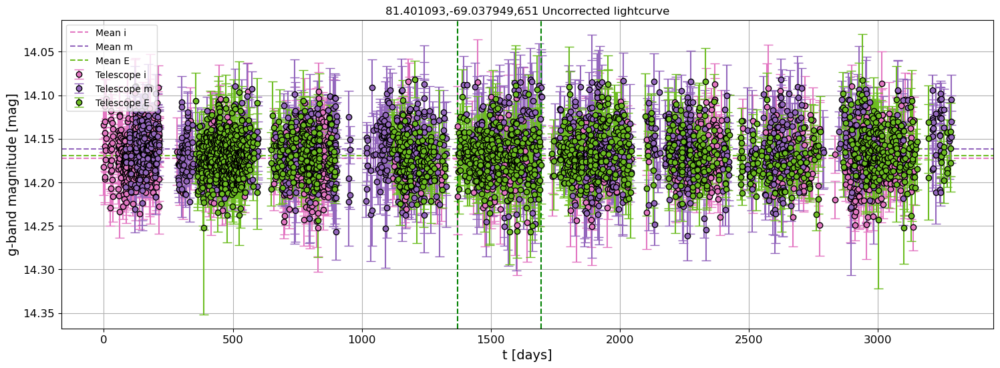

5637 rows read from /Users/shannonbowes/Research/ysg/candidates_and_lcs/2022_asassn_lc_data/asassn_lc_data/sub_oct2026/YSG_V3_individual_20261016/lightcurves/YSG_0651_g.csv
Number of data points after filtering by 'qual' >= 0: 5373
Number of data points after filtering by 'qual' & 55 == 0: 4827


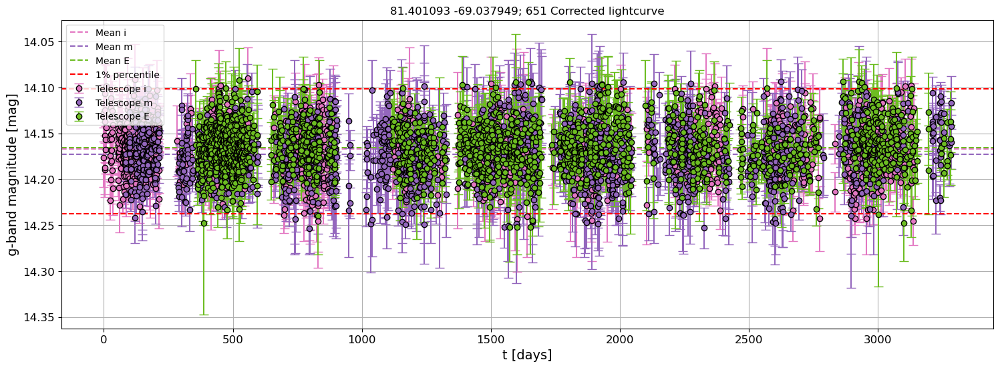

Best frequency: 0.033937 1/day, Best period: 29.47 days, Max power: 0.010, False alarm probability: 2.173e-06
False alarm level for 1.0%: 6.405e-03
Grid sampled at 43152 points


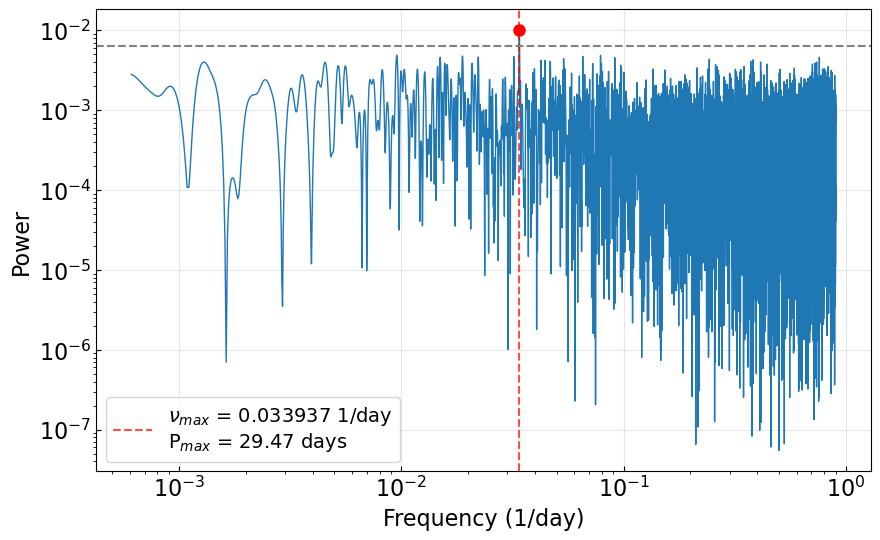

5637 rows read from /Users/shannonbowes/Research/ysg/candidates_and_lcs/2022_asassn_lc_data/asassn_lc_data/sub_oct2026/YSG_V3_individual_20261016/lightcurves/YSG_0651_g.csv
Number of data points after filtering by 'qual' >= 0: 5373
Number of data points after filtering by 'qual' & 55 == 0: 4827
5637 rows read from /Users/shannonbowes/Research/ysg/candidates_and_lcs/2022_asassn_lc_data/asassn_lc_data/sub_oct2026/YSG_V3_individual_20261016/lightcurves/YSG_0651_g.csv
Number of data points after filtering by 'qual' >= 0: 5373
Number of data points after filtering by 'qual' & 55 == 0: 4827
5637 rows read from /Users/shannonbowes/Research/ysg/candidates_and_lcs/2022_asassn_lc_data/asassn_lc_data/sub_oct2026/YSG_V3_individual_20261016/lightcurves/YSG_0651_g.csv
Number of data points after filtering by 'qual' >= 0: 5373
Number of data points after filtering by 'qual' & 55 == 0: 4827


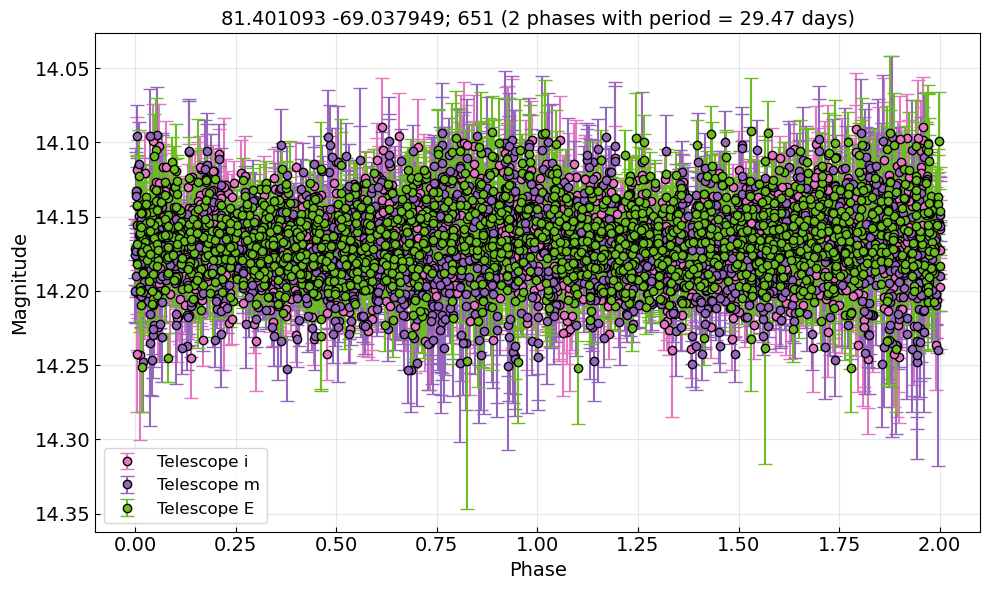

Average scatter (amplitude) per 10 point phase bin: 0.577 mJy
5637 rows read from /Users/shannonbowes/Research/ysg/candidates_and_lcs/2022_asassn_lc_data/asassn_lc_data/sub_oct2026/YSG_V3_individual_20261016/lightcurves/YSG_0651_g.csv
Number of data points after filtering by 'qual' >= 0: 5373
Number of data points after filtering by 'qual' & 55 == 0: 4827
5637 rows read from /Users/shannonbowes/Research/ysg/candidates_and_lcs/2022_asassn_lc_data/asassn_lc_data/sub_oct2026/YSG_V3_individual_20261016/lightcurves/YSG_0651_g.csv
Number of data points after filtering by 'qual' >= 0: 5373
Number of data points after filtering by 'qual' & 55 == 0: 4827
5637 rows read from /Users/shannonbowes/Research/ysg/candidates_and_lcs/2022_asassn_lc_data/asassn_lc_data/sub_oct2026/YSG_V3_individual_20261016/lightcurves/YSG_0651_g.csv
Number of data points after filtering by 'qual' >= 0: 5373
Number of data points after filtering by 'qual' & 55 == 0: 4827


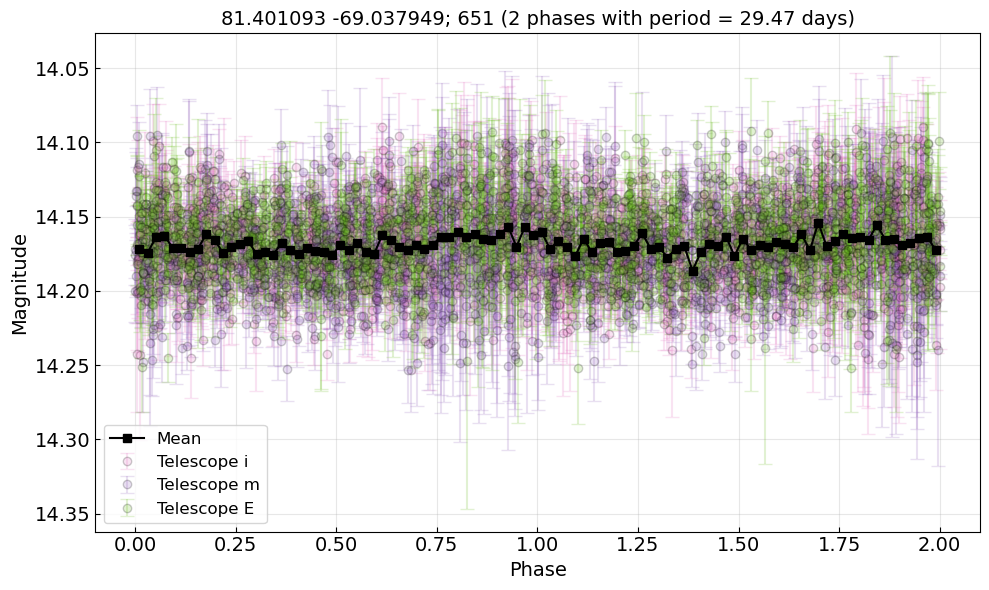

Average scatter (amplitude) per 10 point phase bin: 0.577 mJy
[0.03393681]
Amplitude metrics:
	Lower 5% percentile: 7.49 mJy, 14.12 mags
	Upper 5% percentile: 8.15 mJy, 14.21 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 5% of data) (g-band: True): 0.67 mJy, 0.09 mags
Amplitude metrics:
	Lower 1% percentile: 7.33 mJy, 14.10 mags
	Upper 1% percentile: 8.31 mJy, 14.24 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 1% of data) (g-band: True): 0.98 mJy, 0.14 mags
	Largest amplitude of variability (g-band: True): 1.17 mJy, 0.16 mags
	Average amplitude across all periods: 0.912 mJy
	Standard deviation of amplitudes: 0.133 mJy
	Average amplitude (0.912 mJy) is greater than 5 sigma (0.133 mJy). This indicates consistent variability across periods.


In [19]:
info(651)

Number of stars in first bin (0-10 days): 11


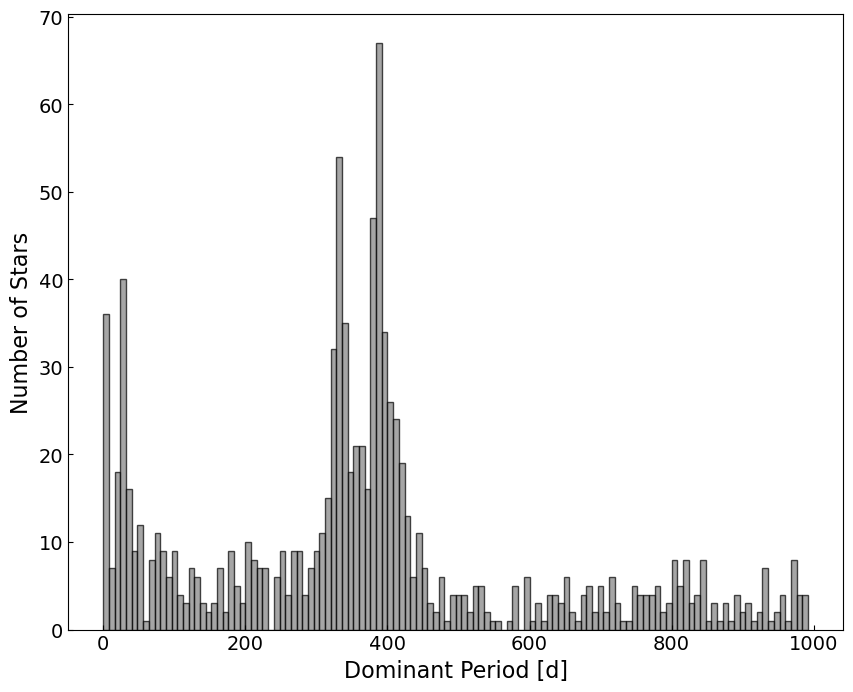

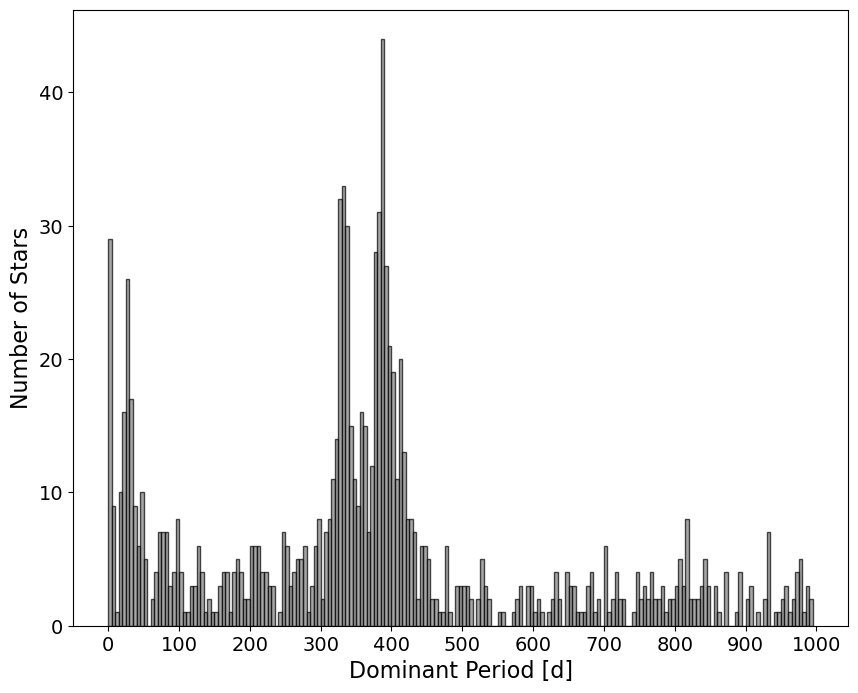

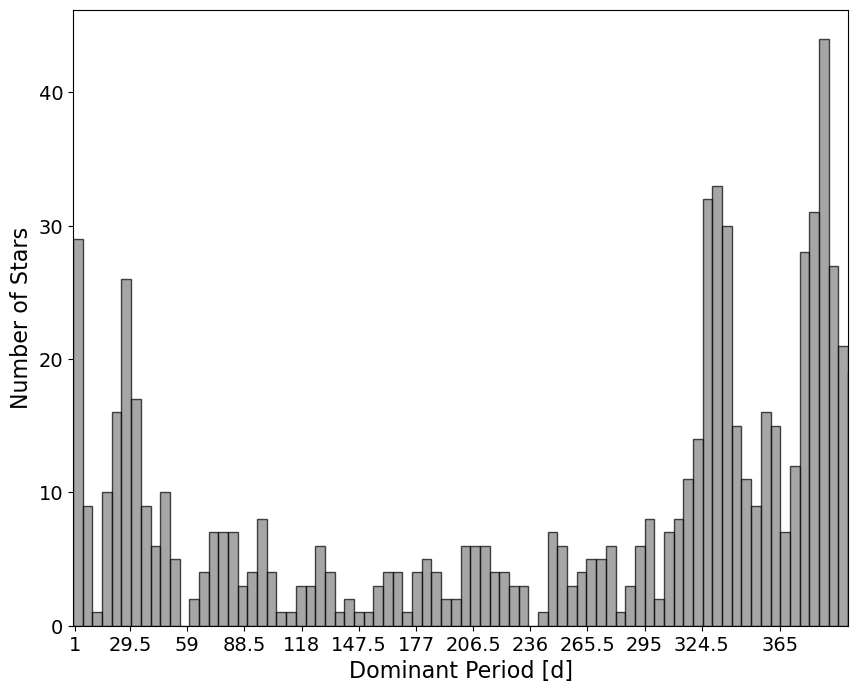

In [23]:
# histogram of periods
sample = sample_oct
# filter out alarm level
sample = sample[sample['alarm_level_flag'] == 0]
fig, ax = plt.subplots(figsize=(10, 8))
ax.hist(sample['best_period'], bins=np.arange(0, 1000, 8), alpha=0.7, color='grey', edgecolor='black')
# print the number ni the first bin
print(f"Number of stars in first bin (0-10 days): {np.sum((sample['best_period'] >= 0) & (sample['best_period'] < 2))}")
ax.set_xlabel("Dominant Period [d]", fontsize=16)
ax.set_ylabel("Number of Stars", fontsize=16)
ax.tick_params(axis="both", direction="in", labelsize=14)
plt.savefig("./figs/period_histogram.png", dpi=300, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(10, 8))
ax.hist(sample['best_period'], bins=np.arange(0, 1000, 5), alpha=0.7, color='grey', edgecolor='black')
ax.set_xlabel("Dominant Period [d]", fontsize=16)
ax.set_ylabel("Number of Stars", fontsize=16)
ax.tick_params(axis="both", direction="out", labelsize=14)
# ax.set_xlim(0,400)
# diy markers on the x axis
# xticks = [1.0, 29.5, 29.5*2, 29.5*3, 29.5*4, 29.5*5, 29.5*6, 29.5*7, 29.5*8, 29.5*9, 29.5*10, 29.5*11, 365]
# ax.set_xticks(xticks)
# ax.set_xticklabels(['1', '29.5', '59', '88.5', '118', '147.5', '177', '206.5', '236', '265.5', '295', '324.5', '365'])
ax.set_xticks(np.arange(0, 1001, 100))
# plt.savefig("./figs/period_histogram.png", dpi=300, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(10, 8))
ax.hist(sample['best_period'], bins=np.arange(0, 1000, 5), alpha=0.7, color='grey', edgecolor='black')
ax.set_xlabel("Dominant Period [d]", fontsize=16)
ax.set_ylabel("Number of Stars", fontsize=16)
ax.tick_params(axis="both", direction="out", labelsize=14)
ax.set_xlim(0,400)
# diy markers on the x axis
xticks = [1.0, 29.5, 29.5*2, 29.5*3, 29.5*4, 29.5*5, 29.5*6, 29.5*7, 29.5*8, 29.5*9, 29.5*10, 29.5*11, 365]
ax.set_xticks(xticks)
ax.set_xticklabels(['1', '29.5', '59', '88.5', '118', '147.5', '177', '206.5', '236', '265.5', '295', '324.5', '365'])
# ax.set_xticks(np.arange(0, 401, 50))
# plt.savefig("./figs/period_histogram.png", dpi=300, bbox_inches="tight")
plt.show()

In [24]:
# print star 1204 df to csv
df, telescopes = df_extract(1204)
df.to_csv('star_1204_lightcurve.csv', index=False)

10937 rows read from /Users/shannonbowes/Research/ysg/candidates_and_lcs/2022_asassn_lc_data/asassn_lc_data/sub_oct2026/YSG_V3_individual_20261016/lightcurves/YSG_1204_g.csv
Number of data points after filtering by 'qual' >= 0: 10783
Number of data points after filtering by 'qual' & 55 == 0: 9445


In [10]:
sample_oct = pd.read_csv(
    './summary_results10202026.csv'
).set_index('star_idx', drop=False)

sample_corner = pd.read_csv(
    './summary_results10202026_nearchipcorner.csv'
).set_index('star_idx', drop=False)
sample_edge = pd.read_csv(
    './summary_results10202026_nearchipedge.csv'
).set_index('star_idx', drop=False)

sample_fwhm = pd.read_csv(
    './summary_results10202026_fwhm.csv'
).set_index('star_idx', drop=False)
sample_wcs = pd.read_csv(
    './summary_results10202026_wcs.csv'
).set_index('star_idx', drop=False)
sample_zipfit = pd.read_csv(
    './summary_results10202026_zipfit.csv'
).set_index('star_idx', drop=False)
sample_throughput = pd.read_csv(
    './summary_results10202026_throughput.csv'
).set_index('star_idx', drop=False)
sample_depth = pd.read_csv(
    './summary_results10202026_depth.csv'
).set_index('star_idx', drop=False)



df_length_oct = sample_oct['df_length'].mean()
mean_length_oct = df_length_oct.mean()
std_length_oct = df_length_oct.std()
#compare the df_length column in each
# df_length_corner = sample_corner['df_length']
# mean_length_corner = df_length_corner.mean()
# std_length_corner = df_length_corner.std()
# print(f"Corner: Mean df_length = {mean_length_corner:.2f}, Std = {std_length_corner:.2f}")
# df_length_edge = sample_edge['df_length']
# mean_length_edge = df_length_edge.mean()
# std_length_edge = df_length_edge.std()
# print(f"Edge: Mean df_length = {mean_length_edge:.2f}, Std = {std_length_edge:.2f}")
# df_length_oct = sample_oct['df_length']
# mean_length_oct = df_length_oct.mean()
# std_length_oct = df_length_oct.std()
# print(f"Oct: Mean df_length = {mean_length_oct:.2f}, Std = {std_length_oct:.2f}")
tables = [sample_oct, sample_corner, sample_edge, sample_fwhm, sample_wcs, sample_zipfit, sample_throughput, sample_depth]
for table in range(len(tables)):
    df_length = tables[table]['df_length']
    mean_length = df_length.mean()
    std_length = df_length.std()
    amplitude = tables[table]['mag_amplitude_1']
    print(f"{['Oct', 'Corner', 'Edge', 'FWHM', 'WCS', 'ZipFit', 'Throughput', 'Depth'][table]}: Percent of data retained compared to just (qual & 55) ==0: {mean_length/df_length_oct*100:.2f}%")
    print(f"Change in period: {(tables[table]['best_period'] - sample_oct['best_period']).mean():.1f} +/- {(tables[table]['best_period'] - sample_oct['best_period']).std():.1f} days, Change in amplitude: {(tables[table]['mag_amplitude_1'] - sample_oct['mag_amplitude_1']).mean():.3f} mag +/- {(tables[table]['mag_amplitude_1'] - sample_oct['mag_amplitude_1']).std():.3f} mag")

Oct: Percent of data retained compared to just (qual & 55) ==0: 100.00%
Change in period: 0.0 +/- 0.0 days, Change in amplitude: 0.000 mag +/- 0.000 mag
Corner: Percent of data retained compared to just (qual & 55) ==0: 99.97%
Change in period: 0.0 +/- 0.5 days, Change in amplitude: -0.000 mag +/- 0.000 mag
Edge: Percent of data retained compared to just (qual & 55) ==0: 98.94%
Change in period: -0.4 +/- 86.1 days, Change in amplitude: -0.000 mag +/- 0.003 mag
FWHM: Percent of data retained compared to just (qual & 55) ==0: 92.38%
Change in period: 2.5 +/- 256.7 days, Change in amplitude: -0.003 mag +/- 0.006 mag
WCS: Percent of data retained compared to just (qual & 55) ==0: 94.17%
Change in period: 5.6 +/- 175.4 days, Change in amplitude: -0.003 mag +/- 0.006 mag
ZipFit: Percent of data retained compared to just (qual & 55) ==0: 94.36%
Change in period: 1.3 +/- 162.9 days, Change in amplitude: -0.005 mag +/- 0.004 mag
Throughput: Percent of data retained compared to just (qual & 55) 